<a href="https://colab.research.google.com/github/Chaki34/Research-paper/blob/main/reserch_paper_test_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
# ===== Cell 1.1: GPU verification =====
import subprocess

print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout
      or "nvidia-smi not found: no GPU runtime attached.")

import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected.\n"
        "Fix: Runtime -> Change runtime type -> Hardware accelerator: T4 GPU, then "
        "Runtime -> Restart session and re-run this cell."
    )

props = torch.cuda.get_device_properties(0)
print(f"GPU name         : {props.name}")
print(f"GPU memory       : {props.total_memory / 1024**3:.1f} GB")
print(f"Compute capability: {props.major}.{props.minor}")
print(f"PyTorch          : {torch.__version__}")
print(f"CUDA (PyTorch)   : {torch.version.cuda}")
print(f"bf16 supported   : {torch.cuda.is_bf16_supported()}")

Thu Nov 26 07:12:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   73C    P0             32W /   70W |    1907MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [38]:
# ===== Cell 1.2: Install dependencies (run once per session) =====
!pip install -q timm grad-cam seaborn scikit-learn opencv-python-headless kaggle

In [39]:
# ===== Cell 1.3: Imports, seeds, device, AMP =====
import os, random, time, copy, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import timm
import sklearn

warnings.filterwarnings("ignore", category=UserWarning)

# ---- Reproducibility ----
SEED = 42

def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    # Deterministic cuDNN is slower; benchmark=False keeps runs comparable.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# DataLoader worker seeding helper (used in Step 3)
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# ---- Device and mixed precision ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_bf16_supported():
    AMP_DTYPE = torch.bfloat16      # Ampere or newer (A100, L4): no GradScaler needed
    USE_GRAD_SCALER = False
else:
    AMP_DTYPE = torch.float16       # T4: needs GradScaler
    USE_GRAD_SCALER = True

# ---- Global config (starting hyperparameters, not tuned optima) ----
CFG = {
    "seed": SEED,
    "img_size": 224,
    "batch_size": 16,               # drop to 8 on CUDA OOM
    "embed_dim": 256,
    "num_classes": 4,
    "class_names": ["glioma", "meningioma", "notumor", "pituitary"],
    "lr_new": 1e-4,
    "lr_backbone": 1e-5,
    "weight_decay": 1e-4,
    "max_epochs": 40,
    "es_patience": 7,
    "imagenet_mean": (0.485, 0.456, 0.406),
    "imagenet_std": (0.229, 0.224, 0.225),
}

print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | "
      f"timm {timm.__version__} | sklearn {sklearn.__version__} | numpy {np.__version__}")
print(f"Device: {DEVICE} | AMP dtype: {AMP_DTYPE} | GradScaler needed: {USE_GRAD_SCALER}")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | timm 1.0.31 | sklearn 1.6.1 | numpy 2.4.6
Device: cuda | AMP dtype: torch.bfloat16 | GradScaler needed: False


In [40]:
# ===== Cell 1.4: Mount Drive and set output paths =====
from google.colab import drive
drive.mount("/content/drive")

WORK_DIR = Path("/content/drive/MyDrive/brain_tumor_bicaf")
CKPT_DIR = WORK_DIR / "checkpoints"
RESULT_DIR = WORK_DIR / "results"
for d in (CKPT_DIR, RESULT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Dataset will live on the fast local disk (not Drive) for quicker loading
DATA_ROOT = Path("/content/data")
DATA_ROOT.mkdir(exist_ok=True)

print("Checkpoints :", CKPT_DIR)
print("Results     :", RESULT_DIR)
print("Dataset root:", DATA_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints : /content/drive/MyDrive/brain_tumor_bicaf/checkpoints
Results     : /content/drive/MyDrive/brain_tumor_bicaf/results
Dataset root: /content/data


In [41]:
# ===== Cell 1.5: Verify pretrained weights and feature shapes =====
def list_available(pattern):
    return timm.list_pretrained(pattern)

print("EfficientNetV2-S tags available:")
for n in list_available("tf_efficientnetv2_s*"):
    print("  ", n)
print("\nSwin-T tags available:")
for n in list_available("swin_tiny_patch4_window7_224*"):
    print("  ", n)

# Candidates in priority order (first one that loads is used)
EFFNET_CANDIDATES = [
    "tf_efficientnetv2_s.in21k_ft_in1k",
    "tf_efficientnetv2_s.in1k",
]
SWIN_CANDIDATES = [
    "swin_tiny_patch4_window7_224.ms_in22k_ft_in1k",
    "swin_tiny_patch4_window7_224.ms_in1k",
]

def load_first_available(candidates):
    last_err = None
    for name in candidates:
        try:
            m = timm.create_model(name, pretrained=True, num_classes=0)  # num_classes=0 removes head
            print(f"[OK] Loaded pretrained weights: {name}")
            return name, m
        except Exception as e:
            last_err = e
            print(f"[FAIL] {name}: {type(e).__name__}: {str(e)[:150]}")
    raise RuntimeError(
        f"None of {candidates} could be loaded. Last error: {last_err}\n"
        "Check: internet connection in Colab, Hugging Face Hub access, timm version "
        "(pip install -U timm), or choose a tag from the lists printed above."
    )

EFFNET_NAME, effnet = load_first_available(EFFNET_CANDIDATES)
SWIN_NAME, swin = load_first_available(SWIN_CANDIDATES)
effnet.eval(); swin.eval()

dummy = torch.randn(2, 3, CFG["img_size"], CFG["img_size"])
with torch.no_grad():
    f_eff = effnet.forward_features(dummy)
    f_swin = swin.forward_features(dummy)

print("\nEfficientNetV2-S feature map:", tuple(f_eff.shape), " (expected [B, 1280, 7, 7], NCHW)")
print("Swin-T feature map          :", tuple(f_swin.shape), " (expected [B, 7, 7, 768], NHWC in recent timm)")

# Record layout for Step 4, so the projection permutes correctly
SWIN_IS_NHWC = (f_swin.dim() == 4 and f_swin.shape[-1] == 768)
EFF_CH = f_eff.shape[1]
SWIN_CH = f_swin.shape[-1] if SWIN_IS_NHWC else f_swin.shape[1]
print(f"\nSwin output layout NHWC: {SWIN_IS_NHWC} | EFF channels: {EFF_CH} | Swin channels: {SWIN_CH}")

n_eff = sum(p.numel() for p in effnet.parameters()) / 1e6
n_swin = sum(p.numel() for p in swin.parameters()) / 1e6
print(f"Params (headless): EfficientNetV2-S {n_eff:.2f}M | Swin-T {n_swin:.2f}M")

del effnet, swin, dummy, f_eff, f_swin
torch.cuda.empty_cache()

EfficientNetV2-S tags available:
   tf_efficientnetv2_s.in1k
   tf_efficientnetv2_s.in21k
   tf_efficientnetv2_s.in21k_ft_in1k

Swin-T tags available:
   swin_tiny_patch4_window7_224.ms_in1k
   swin_tiny_patch4_window7_224.ms_in22k
   swin_tiny_patch4_window7_224.ms_in22k_ft_in1k
[OK] Loaded pretrained weights: tf_efficientnetv2_s.in21k_ft_in1k
[OK] Loaded pretrained weights: swin_tiny_patch4_window7_224.ms_in22k_ft_in1k

EfficientNetV2-S feature map: (2, 1280, 7, 7)  (expected [B, 1280, 7, 7], NCHW)
Swin-T feature map          : (2, 7, 7, 768)  (expected [B, 7, 7, 768], NHWC in recent timm)

Swin output layout NHWC: True | EFF channels: 1280 | Swin channels: 768
Params (headless): EfficientNetV2-S 20.18M | Swin-T 27.52M


In [42]:
# ===== Cell 1.6: Memory and AMP smoke test =====
def smoke_test(batch_size):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    eff = timm.create_model(EFFNET_NAME, pretrained=False, num_classes=0).to(DEVICE).train()
    swn = timm.create_model(SWIN_NAME, pretrained=False, num_classes=0).to(DEVICE).train()
    x = torch.randn(batch_size, 3, CFG["img_size"], CFG["img_size"], device=DEVICE)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_GRAD_SCALER)
    try:
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
            out = eff(x).float().mean() + swn(x).float().mean()   # pooled features, dummy loss
        scaler.scale(out).backward()
        torch.cuda.synchronize()
        peak = torch.cuda.max_memory_allocated() / 1024**3
        print(f"Batch {batch_size}: OK | peak GPU memory {peak:.2f} GB "
              f"of {props.total_memory/1024**3:.1f} GB")
        return True
    except torch.cuda.OutOfMemoryError:
        print(f"Batch {batch_size}: CUDA OOM. Try a smaller batch size.")
        return False
    finally:
        del eff, swn, x
        torch.cuda.empty_cache()

for bs in (CFG["batch_size"], 8):
    if smoke_test(bs):
        CFG["batch_size"] = bs
        break
print("Selected batch size:", CFG["batch_size"])

/tmp/ipykernel_522/1667960794.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_GRAD_SCALER)


Batch 16: OK | peak GPU memory 3.02 GB of 14.6 GB
Selected batch size: 16


In [43]:
# ===== Cell 2.1: Download dataset =====
!pip install -q kagglehub
import kagglehub, subprocess, shutil

DATASET_SLUG = "masoudnickparvar/brain-tumor-mri-dataset"

def download_with_kaggle_cli():
    from google.colab import files
    print("Upload kaggle.json (Kaggle > Settings > API > Create New Token)")
    up = files.upload()
    kdir = Path(os.path.expanduser("~/.kaggle")); kdir.mkdir(exist_ok=True)
    (kdir / "kaggle.json").write_bytes(up["kaggle.json"])
    os.chmod(kdir / "kaggle.json", 0o600)
    subprocess.run(["kaggle", "datasets", "download", "-d", DATASET_SLUG,
                    "-p", str(DATA_ROOT), "--unzip"], check=True)
    return DATA_ROOT

try:
    DATASET_PATH = Path(kagglehub.dataset_download(DATASET_SLUG))
    print("Downloaded via kagglehub")
except Exception as e:
    print(f"kagglehub failed ({type(e).__name__}: {str(e)[:120]}). Falling back to Kaggle CLI.")
    DATASET_PATH = download_with_kaggle_cli()

def find_dir(root, name):
    for p in sorted(Path(root).rglob("*")):
        if p.is_dir() and p.name.lower() == name.lower():
            # must contain the 4 class folders
            if all((p / c).is_dir() for c in CFG["class_names"]):
                return p
    raise FileNotFoundError(
        f"Could not find '{name}' with class folders {CFG['class_names']} under {root}. "
        "Print the tree with: !find {root} -maxdepth 3 -type d")

TRAIN_DIR = find_dir(DATASET_PATH, "Training")
TEST_DIR = find_dir(DATASET_PATH, "Testing")
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Downloaded via kagglehub
TRAIN_DIR: /kaggle/input/brain-tumor-mri-dataset/Training
TEST_DIR : /kaggle/input/brain-tumor-mri-dataset/Testing


In [44]:
# ===== Cell 2.2: File index and count check =====
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
CLASS_TO_IDX = {c: i for i, c in enumerate(CFG["class_names"])}

rows, skipped = [], []
for split_name, root in (("train", TRAIN_DIR), ("test", TEST_DIR)):
    for cls in CFG["class_names"]:
        for f in sorted((root / cls).iterdir()):
            if f.is_file() and f.suffix.lower() in IMG_EXTS:
                rows.append({"path": str(f), "split": split_name,
                             "class": cls, "label": CLASS_TO_IDX[cls]})
            else:
                skipped.append(str(f))

df = pd.DataFrame(rows)
print("Skipped non-image entries:", len(skipped), skipped[:5])
print("\nCounts per split/class:")
print(pd.crosstab(df["class"], df["split"], margins=True))

EXPECTED = {"train": 5712, "test": 1311}
for s, n in EXPECTED.items():
    got = (df["split"] == s).sum()
    status = "MATCH" if got == n else "MISMATCH (document this: dataset version may differ)"
    print(f"{s}: found {got}, paper {n} -> {status}")

Skipped non-image entries: 0 []

Counts per split/class:
split       test  train   All
class                        
glioma       400   1400  1800
meningioma   400   1400  1800
notumor      400   1400  1800
pituitary    400   1400  1800
All         1600   5600  7200
train: found 5600, paper 5712 -> MISMATCH (document this: dataset version may differ)
test: found 1600, paper 1311 -> MISMATCH (document this: dataset version may differ)


In [45]:
# ===== Cell 2.3: Corruption, duplicate and overlap checks =====
from tqdm.auto import tqdm
import hashlib

def md5_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def dhash64(im):
    g = np.asarray(im.convert("L").resize((9, 8), Image.LANCZOS), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()                 # 64 bits
    return int.from_bytes(np.packbits(bits).tobytes(), "big")

recs = []
for p in tqdm(df["path"], desc="Checking images"):
    r = {"md5": None, "ok": True, "err": "", "w": 0, "h": 0, "mode": "", "dhash": 0}
    try:
        r["md5"] = md5_file(p)
        with Image.open(p) as im:
            im.verify()                                      # structural check
        with Image.open(p) as im:
            im.load()                                        # full decode check
            r["w"], r["h"], r["mode"] = im.size[0], im.size[1], im.mode
            r["dhash"] = dhash64(im)
    except Exception as e:
        r["ok"], r["err"] = False, f"{type(e).__name__}: {e}"
    recs.append(r)

df = pd.concat([df.reset_index(drop=True), pd.DataFrame(recs)], axis=1)
df["dhash"] = df["dhash"].astype("uint64")

# ---- 1. Corrupted images ----
bad = df[~df["ok"]]
print(f"Corrupted/unreadable images: {len(bad)}")
if len(bad):
    print(bad[["path", "err"]].to_string())

good = df[df["ok"]]

# ---- 2. Exact duplicates (identical bytes) ----
train_md5 = set(good.loc[good.split == "train", "md5"])
test_md5 = set(good.loc[good.split == "test", "md5"])
n_train_extra = (good.split == "train").sum() - len(train_md5)
n_test_extra = (good.split == "test").sum() - len(test_md5)
cross_md5 = train_md5 & test_md5
label_conflicts = good.groupby("md5")["label"].nunique()
label_conflicts = label_conflicts[label_conflicts > 1]

print(f"\nExact duplicates within train (extra copies): {n_train_extra}")
print(f"Exact duplicates within test  (extra copies): {n_test_extra}")
print(f"Exact train-test overlap (identical files)  : {len(cross_md5)} unique hashes")
print(f"Identical files with conflicting labels     : {len(label_conflicts)}")

# ---- 3. Near-duplicates across train/test via difference hash ----
LUT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def min_hamming(a, b, chunk=256):
    """For each hash in a, the minimum Hamming distance to any hash in b."""
    out = np.empty(len(a), dtype=np.int16)
    for i in range(0, len(a), chunk):
        x = np.ascontiguousarray(np.bitwise_xor(a[i:i + chunk, None], b[None, :]))
        d = LUT[x.view(np.uint8).reshape(x.shape + (8,))].sum(-1)
        out[i:i + chunk] = d.min(axis=1)
    return out

h_train = good.loc[good.split == "train", "dhash"].to_numpy(dtype=np.uint64)
h_test = good.loc[good.split == "test", "dhash"].to_numpy(dtype=np.uint64)
test_min = min_hamming(h_test, h_train)

print("\nTest images with a near-identical training image (dHash distance):")
for t in (0, 2, 4):
    print(f"  distance <= {t}: {(test_min <= t).sum()} / {len(test_min)}")
print("Note: distance 0 is a strong duplicate signal; 1-4 are candidates only. "
      "Neighbouring MRI slices can look alike, so inspect them visually before concluding.")

# ---- 4. Image size / mode summary ----
print("\nImage modes:", good["mode"].value_counts().to_dict())
print("Unique image sizes:", good[["w", "h"]].drop_duplicates().shape[0])
print(good[["w", "h"]].describe().loc[["min", "max", "mean"]].round(1))

# ---- 5. Save report (kept on your Drive for the final write-up) ----
integrity_report = {
    "n_total": int(len(df)), "n_corrupted": int(len(bad)),
    "exact_dups_train_extra": int(n_train_extra), "exact_dups_test_extra": int(n_test_extra),
    "exact_train_test_overlap_hashes": int(len(cross_md5)),
    "label_conflicts": int(len(label_conflicts)),
    "near_dup_test_vs_train_dist0": int((test_min <= 0).sum()),
    "near_dup_test_vs_train_dist<=4": int((test_min <= 4).sum()),
}
with open(RESULT_DIR / "integrity_report.json", "w") as f:
    json.dump(integrity_report, f, indent=2)
print("\nSaved:", RESULT_DIR / "integrity_report.json")

Checking images:   0%|          | 0/7200 [00:00<?, ?it/s]

Corrupted/unreadable images: 0

Exact duplicates within train (extra copies): 171
Exact duplicates within test  (extra copies): 16
Exact train-test overlap (identical files)  : 0 unique hashes
Identical files with conflicting labels     : 0

Test images with a near-identical training image (dHash distance):
  distance <= 0: 372 / 1600
  distance <= 2: 565 / 1600
  distance <= 4: 852 / 1600
Note: distance 0 is a strong duplicate signal; 1-4 are candidates only. Neighbouring MRI slices can look alike, so inspect them visually before concluding.

Image modes: {'RGB': 4129, 'L': 3067, 'RGBA': 3, 'P': 1}
Unique image sizes: 447
           w       h
min    150.0   167.0
max   1375.0  1446.0
mean   453.3   456.9

Saved: /content/drive/MyDrive/brain_tumor_bicaf/results/integrity_report.json


In [46]:
# ===== Cell 2.4: Train/validation split =====
from sklearn.model_selection import StratifiedGroupKFold

# Set True ONLY if Cell 2.3 showed exact train-test overlap AND you want to remove
# those images from training. Default False = report only, change nothing silently.
EXCLUDE_TRAIN_TEST_OVERLAP = False

full_train = good[good.split == "train"].reset_index(drop=True)
test_df = good[good.split == "test"].reset_index(drop=True)

if EXCLUDE_TRAIN_TEST_OVERLAP and len(cross_md5):
    before = len(full_train)
    full_train = full_train[~full_train["md5"].isin(test_md5)].reset_index(drop=True)
    print(f"Removed {before - len(full_train)} training images identical to test images "
          "(DOCUMENT THIS in your report).")

# 5 folds, take the first as validation -> 80:20, stratified, grouped by exact duplicate
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(full_train, full_train["label"], groups=full_train["md5"]))
train_df = full_train.iloc[tr_idx].reset_index(drop=True)
val_df = full_train.iloc[va_idx].reset_index(drop=True)

# ---- Sanity checks ----
assert set(train_df["path"]).isdisjoint(val_df["path"]), "Path leakage between train and val!"
assert set(train_df["md5"]).isdisjoint(val_df["md5"]), "Duplicate leakage between train and val!"
assert all("Testing" not in p and p.startswith(str(TRAIN_DIR)) for p in
           list(train_df["path"]) + list(val_df["path"])), "Test path found in train/val!"

print(f"Train: {len(train_df)} ({len(train_df)/len(full_train):.1%}) | "
      f"Val: {len(val_df)} ({len(val_df)/len(full_train):.1%}) | Test: {len(test_df)}")

dist = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "val": val_df["class"].value_counts(),
    "test": test_df["class"].value_counts(),
}).loc[CFG["class_names"]]
dist_pct = (dist / dist.sum() * 100).round(1)
print("\nClass counts:\n", dist)
print("\nClass share (%):\n", dist_pct)

# ---- Is class weighting justified? (decided from training counts only) ----
counts = train_df["class"].value_counts()
ratio = counts.max() / counts.min()
print(f"\nTrain imbalance ratio (largest/smallest class): {ratio:.2f}")
print("Interpretation: <1.5 = mild imbalance, class weights probably unnecessary "
      "(we still test them as a controlled experiment in the later steps).")

# ---- Save the exact split so every experiment reuses identical partitions ----
train_df.to_csv(RESULT_DIR / "split_train.csv", index=False)
val_df.to_csv(RESULT_DIR / "split_val.csv", index=False)
test_df.to_csv(RESULT_DIR / "split_test.csv", index=False)
print("Saved split CSVs to", RESULT_DIR)

Train: 4481 (80.0%) | Val: 1119 (20.0%) | Test: 1600

Class counts:
             train  val  test
class                       
glioma       1142  258   400
meningioma   1115  285   400
notumor      1104  296   400
pituitary    1120  280   400

Class share (%):
             train   val  test
class                        
glioma       25.5  23.1  25.0
meningioma   24.9  25.5  25.0
notumor      24.6  26.5  25.0
pituitary    25.0  25.0  25.0

Train imbalance ratio (largest/smallest class): 1.03
Interpretation: <1.5 = mild imbalance, class weights probably unnecessary (we still test them as a controlled experiment in the later steps).
Saved split CSVs to /content/drive/MyDrive/brain_tumor_bicaf/results


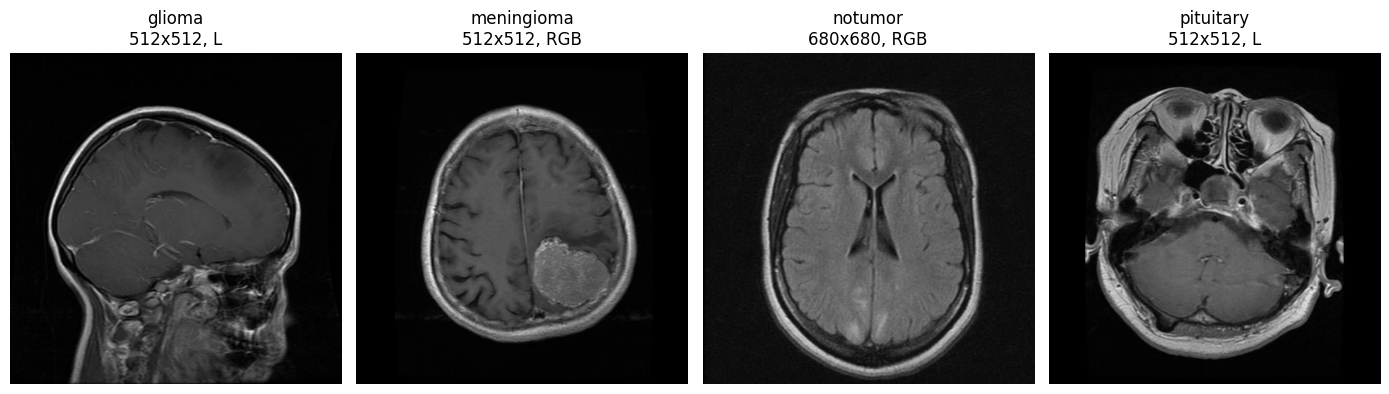

In [47]:
# ===== Cell 2.5: Sample images =====
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, cls in zip(axes, CFG["class_names"]):
    row = train_df[train_df["class"] == cls].sample(1, random_state=rng).iloc[0]
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    ax.set_title(f"{cls}\n{row['w']}x{row['h']}, {row['mode']}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [48]:
# ===== Cell 3.1: Transforms =====
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

IMG = CFG["img_size"]
MEAN, STD = CFG["imagenet_mean"], CFG["imagenet_std"]
BICUBIC = T.InterpolationMode.BICUBIC
BILINEAR = T.InterpolationMode.BILINEAR

# Training-only: moderate, anatomy-preserving augmentation
train_tf = T.Compose([
    T.Resize((IMG, IMG), interpolation=BICUBIC),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10,                 # small rotation
                   translate=(0.05, 0.05),     # up to 5% shift
                   scale=(0.95, 1.05),         # up to 5% zoom
                   interpolation=BILINEAR,
                   fill=0),                    # black background matches MRI
    T.ColorJitter(brightness=0.1, contrast=0.1),   # mild only; no hue/saturation
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

# Validation / test: fully deterministic, no randomness
eval_tf = T.Compose([
    T.Resize((IMG, IMG), interpolation=BICUBIC),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

# Helper to undo normalization for visualization
_mean = torch.tensor(MEAN).view(3, 1, 1)
_std = torch.tensor(STD).view(3, 1, 1)
def denormalize(x):
    return (x.cpu() * _std + _mean).clamp(0, 1)

print("Train transform:\n", train_tf)
print("\nEval transform:\n", eval_tf)

Train transform:
 Compose(
    Resize(size=(224, 224), interpolation=bicubic, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-10.0, 10.0], translate=(0.05, 0.05), scale=(0.95, 1.05), interpolation=bilinear)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)

Eval transform:
 Compose(
    Resize(size=(224, 224), interpolation=bicubic, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


In [49]:
# ===== Cell 3.2: Dataset and DataLoaders =====
class BrainMRIDataset(Dataset):
    def __init__(self, df, transform, return_path=False):
        self.paths = df["path"].tolist()
        self.labels = df["label"].astype(int).tolist()
        self.transform = transform
        self.return_path = return_path

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        path = self.paths[i]
        try:
            with Image.open(path) as im:
                img = im.convert("RGB")        # L / RGBA / P  ->  3-channel RGB
        except Exception as e:
            raise RuntimeError(f"Failed to load image: {path} ({type(e).__name__}: {e})")
        x = self.transform(img)
        y = self.labels[i]
        return (x, y, path) if self.return_path else (x, y)

train_ds = BrainMRIDataset(train_df, train_tf)
val_ds = BrainMRIDataset(val_df, eval_tf)
test_ds = BrainMRIDataset(test_df, eval_tf)

# Colab typically has 2 CPU cores; more workers rarely help
NUM_WORKERS = min(2, os.cpu_count() or 1)
EVAL_BATCH = 32

g = torch.Generator()
g.manual_seed(SEED)

def make_loader(ds, batch_size, shuffle, drop_last=False):
    return DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last,
        num_workers=NUM_WORKERS, pin_memory=True,
        worker_init_fn=seed_worker, generator=g,
        persistent_workers=NUM_WORKERS > 0,
    )

# drop_last=True on train avoids a size-1 final batch, which breaks BatchNorm in the head
train_loader = make_loader(train_ds, CFG["batch_size"], shuffle=True, drop_last=True)
val_loader = make_loader(val_ds, EVAL_BATCH, shuffle=False)
test_loader = make_loader(test_ds, EVAL_BATCH, shuffle=False)

print(f"Train: {len(train_ds)} imgs, {len(train_loader)} batches of {CFG['batch_size']}")
print(f"Val  : {len(val_ds)} imgs, {len(val_loader)} batches of {EVAL_BATCH}")
print(f"Test : {len(test_ds)} imgs, {len(test_loader)} batches of {EVAL_BATCH}")
print(f"num_workers = {NUM_WORKERS}")

Train: 4481 imgs, 280 batches of 16
Val  : 1119 imgs, 35 batches of 32
Test : 1600 imgs, 50 batches of 32
num_workers = 2


In [50]:
# ===== Cell 3.3: Sanity checks =====
# ---- 1. One training batch ----
xb, yb = next(iter(train_loader))
print("Train batch:", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape), yb.dtype)
assert xb.shape == (CFG["batch_size"], 3, IMG, IMG), "Unexpected image tensor shape"
assert torch.isfinite(xb).all(), "NaN/Inf in input batch"
assert yb.min() >= 0 and yb.max() < CFG["num_classes"], "Label out of range"
print(f"Normalized pixel range: min {xb.min():.2f}, max {xb.max():.2f}, "
      f"mean {xb.mean():.2f}, std {xb.std():.2f}")
print("Label counts in this batch:", torch.bincount(yb, minlength=4).tolist())

# ---- 2. Eval transform must be deterministic ----
a, _ = val_ds[0]
b, _ = val_ds[0]
assert torch.equal(a, b), "Validation transform is NOT deterministic!"
print("Eval transform deterministic: OK")

# ---- 3. Train transform should be random ----
c, _ = train_ds[0]
d, _ = train_ds[0]
print("Train transform random (two loads differ):", not torch.equal(c, d))

# ---- 4. Loader label order matches DataFrame (val, no shuffle) ----
_, yv = next(iter(val_loader))
assert yv.tolist() == val_df["label"].iloc[:len(yv)].tolist(), "Val loader order mismatch"
print("Val loader order matches DataFrame: OK")

# ---- 5. Loader speed (input pipeline should not bottleneck the GPU) ----
t0 = time.time()
n = 0
for i, (x, y) in enumerate(train_loader):
    n += x.size(0)
    if i == 19:
        break
dt = time.time() - t0
print(f"Loader throughput: {n/dt:.0f} images/s over 20 batches")

Train batch: (16, 3, 224, 224) torch.float32 | labels: (16,) torch.int64
Normalized pixel range: min -2.12, max 2.64, mean -1.07, std 0.90
Label counts in this batch: [4, 4, 4, 4]
Eval transform deterministic: OK
Train transform random (two loads differ): True
Val loader order matches DataFrame: OK
Loader throughput: 40 images/s over 20 batches


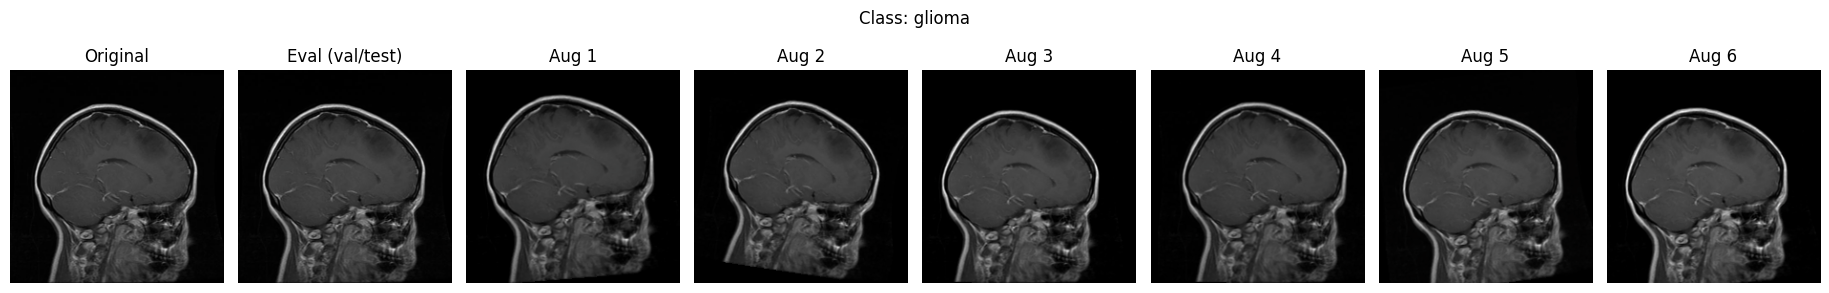

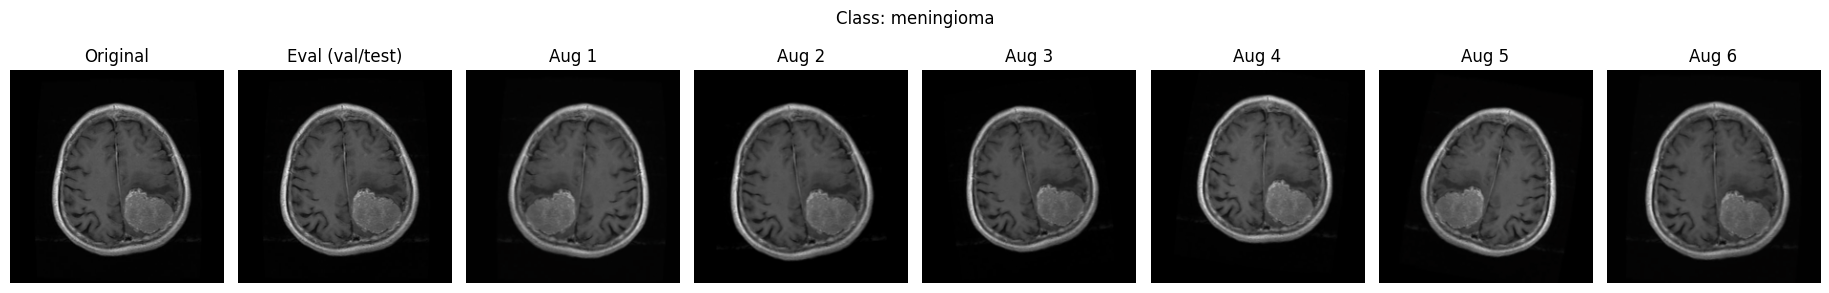

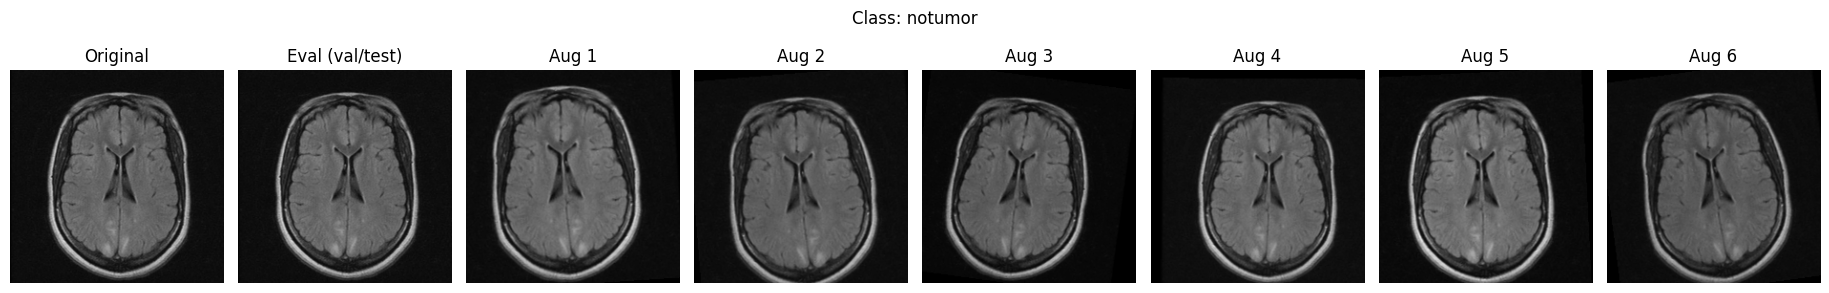

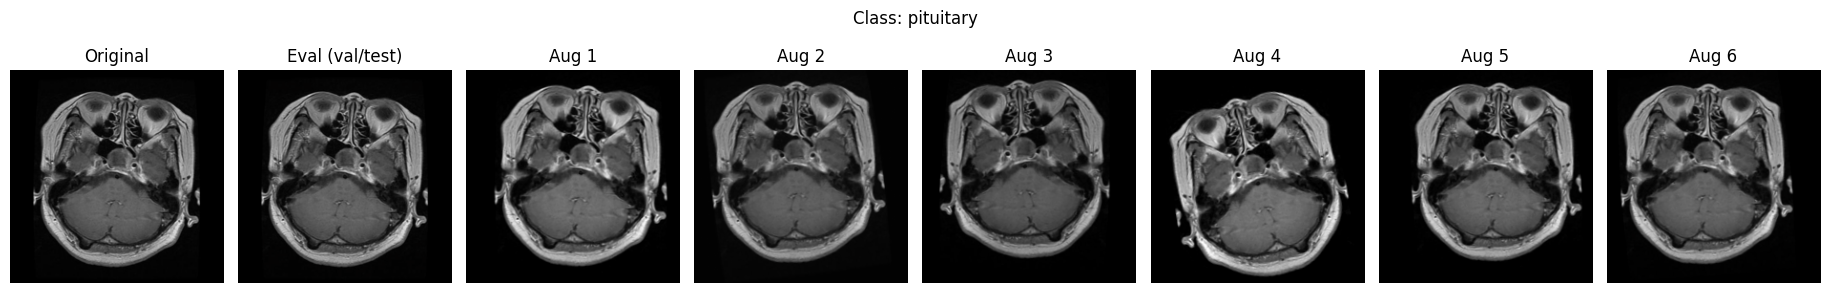

In [51]:
# ===== Cell 3.4: Augmentation preview =====
def show_augmentations(row, n_aug=6):
    img = Image.open(row["path"]).convert("RGB")
    fig, axes = plt.subplots(1, n_aug + 2, figsize=(2.3 * (n_aug + 2), 2.9))
    axes[0].imshow(img.resize((IMG, IMG)))
    axes[0].set_title("Original")
    axes[1].imshow(denormalize(eval_tf(img)).permute(1, 2, 0))
    axes[1].set_title("Eval (val/test)")
    for k in range(n_aug):
        axes[k + 2].imshow(denormalize(train_tf(img)).permute(1, 2, 0))
        axes[k + 2].set_title(f"Aug {k+1}")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"Class: {row['class']}", y=1.02)
    plt.tight_layout()
    plt.show()

rng = np.random.RandomState(SEED)
for cls in CFG["class_names"]:
    row = train_df[train_df["class"] == cls].sample(1, random_state=rng).iloc[0]
    show_augmentations(row)

In [52]:
# ===== Cell 3.5: Class weights (computed, not applied) =====
train_counts = train_df["label"].value_counts().sort_index()
print("Training counts:", dict(zip(CFG["class_names"], train_counts.tolist())))

# weight_c = N / (K * n_c)  (same convention as sklearn's 'balanced')
N, K = train_counts.sum(), CFG["num_classes"]
class_weights = torch.tensor(N / (K * train_counts.values), dtype=torch.float32)
print("Candidate class weights:", dict(zip(CFG["class_names"], class_weights.round(decimals=3).tolist())))
print("Imbalance ratio (max/min):", round(train_counts.max() / train_counts.min(), 2))

Training counts: {'glioma': 1142, 'meningioma': 1115, 'notumor': 1104, 'pituitary': 1120}
Candidate class weights: {'glioma': 0.9810000061988831, 'meningioma': 1.0049999952316284, 'notumor': 1.0149999856948853, 'pituitary': 1.0}
Imbalance ratio (max/min): 1.03


In [53]:
# ===== Cell 4.1: Projection + cross-attention + bidirectional fusion =====
class TokenProjection(nn.Module):
    """Project backbone tokens [B,N,C] -> [B,N,D], LayerNorm, add learnable positional embedding."""
    def __init__(self, in_dim, embed_dim, n_tokens, drop=0.0):
        super().__init__()
        self.proj = nn.Linear(in_dim, embed_dim)
        self.norm = nn.LayerNorm(embed_dim)
        self.pos = nn.Parameter(torch.zeros(1, n_tokens, embed_dim))
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.drop = nn.Dropout(drop)

    def forward(self, tokens):
        x = self.norm(self.proj(tokens))
        return self.drop(x + self.pos)


class MultiHeadCrossAttention(nn.Module):
    """Attention(Q,K,V) = softmax(QK^T / sqrt(d_head)) V.  Q from xq; K,V from xkv."""
    def __init__(self, dim, num_heads=8, attn_drop=0.1):
        super().__init__()
        assert dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.h, self.dh = num_heads, dim // num_heads
        self.scale = self.dh ** -0.5
        self.q = nn.Linear(dim, dim)
        self.k = nn.Linear(dim, dim)
        self.v = nn.Linear(dim, dim)
        self.out = nn.Linear(dim, dim)
        self.attn_drop = nn.Dropout(attn_drop)
        self.store_attn = False        # set True to keep attention maps for visualization
        self.last_attn = None

    def forward(self, xq, xkv):
        B, Nq, D = xq.shape
        Nk = xkv.shape[1]
        q = self.q(xq).view(B, Nq, self.h, self.dh).transpose(1, 2)    # [B,h,Nq,dh]
        k = self.k(xkv).view(B, Nk, self.h, self.dh).transpose(1, 2)   # [B,h,Nk,dh]
        v = self.v(xkv).view(B, Nk, self.h, self.dh).transpose(1, 2)   # [B,h,Nk,dh]
        attn = (q @ k.transpose(-2, -1)) * self.scale                  # [B,h,Nq,Nk]
        attn = attn.softmax(dim=-1)
        if self.store_attn:
            self.last_attn = attn.detach().float().cpu()
        attn = self.attn_drop(attn)
        out = (attn @ v).transpose(1, 2).reshape(B, Nq, D)             # [B,Nq,D]
        return self.out(out)


class CrossAttentionBlock(nn.Module):
    """Cross-attention + dropout + residual (on the query stream) + LayerNorm."""
    def __init__(self, dim, num_heads=8, attn_drop=0.1, drop=0.1):
        super().__init__()
        self.attn = MultiHeadCrossAttention(dim, num_heads, attn_drop)
        self.drop = nn.Dropout(drop)
        self.norm = nn.LayerNorm(dim)

    def forward(self, xq, xkv):
        return self.norm(xq + self.drop(self.attn(xq, xkv)))


class BidirectionalFusion(nn.Module):
    """
    Direction 1: CNN tokens (Q) attend to Swin tokens (K,V)
    Direction 2: Swin tokens (Q) attend to CNN tokens (K,V)
    Token-wise learnable gate g = sigmoid(W [a ; b]);  fused = LN(g*a + (1-g)*b)
    Token i in both branches is the same 7x7 grid cell, so the gate mixes aligned tokens.
    """
    def __init__(self, dim, num_heads=8, attn_drop=0.1, drop=0.1):
        super().__init__()
        self.cnn_to_swin = CrossAttentionBlock(dim, num_heads, attn_drop, drop)
        self.swin_to_cnn = CrossAttentionBlock(dim, num_heads, attn_drop, drop)
        self.gate = nn.Sequential(nn.Linear(2 * dim, dim), nn.Sigmoid())
        self.out_norm = nn.LayerNorm(dim)
        self.last_gate_mean = None

    def forward(self, cnn, swin):
        a = self.cnn_to_swin(cnn, swin)          # CNN queries, Swin keys/values
        b = self.swin_to_cnn(swin, cnn)          # Swin queries, CNN keys/values
        g = self.gate(torch.cat([a, b], dim=-1))
        self.last_gate_mean = g.detach().float().mean()   # no GPU sync; read later
        return self.out_norm(g * a + (1 - g) * b)

print("Modules defined: TokenProjection, MultiHeadCrossAttention, CrossAttentionBlock, BidirectionalFusion")

Modules defined: TokenProjection, MultiHeadCrossAttention, CrossAttentionBlock, BidirectionalFusion


In [54]:
# ===== Cell 4.2: Models and factory =====
CFG.update({"num_heads": 8, "attn_drop": 0.1, "fusion_drop": 0.1, "head_drop": 0.3})

def tokens_from_effnet(f):      # [B,C,H,W] -> [B,HW,C]
    return f.flatten(2).transpose(1, 2)

def tokens_from_swin(f):        # NHWC [B,H,W,C] (new timm) or NCHW (old timm) -> [B,HW,C]
    return f.flatten(1, 2) if SWIN_IS_NHWC else f.flatten(2).transpose(1, 2)


class ClassifierHead(nn.Module):
    """Dense -> Norm -> GELU -> Dropout -> 4-class logits (use with CrossEntropyLoss)."""
    def __init__(self, in_dim, hidden=256, num_classes=4, drop=0.3):
        super().__init__()
        self.fc = nn.Linear(in_dim, hidden)
        self.norm = nn.LayerNorm(hidden)
        self.act = nn.GELU()
        self.drop = nn.Dropout(drop)
        self.out = nn.Linear(hidden, num_classes)

    def forward(self, x):
        return self.out(self.drop(self.act(self.norm(self.fc(x)))))


class FreezeMixin:
    """Frozen backbones keep BatchNorm running stats fixed even when model.train() is called."""
    backbones_frozen = False

    def freeze_backbones(self):
        for m in self._backbones():
            for p in m.parameters():
                p.requires_grad = False
            m.eval()
        self.backbones_frozen = True

    def train(self, mode=True):
        super().train(mode)
        if mode and self.backbones_frozen:
            for m in self._backbones():
                m.eval()
        return self


class HybridNet(FreezeMixin, nn.Module):
    def __init__(self, fusion_mode="bi", embed_dim=256, num_heads=8, attn_drop=0.1,
                 drop=0.1, head_drop=0.3, img_size=224, pretrained=True, num_classes=4):
        super().__init__()
        assert fusion_mode in ("bi", "uni", "concat")
        self.fusion_mode = fusion_mode
        self.eff = timm.create_model(EFFNET_NAME, pretrained=pretrained, num_classes=0)
        self.swin = timm.create_model(SWIN_NAME, pretrained=pretrained, num_classes=0)

        # infer token shapes with a dummy pass (no hard-coded 49 / 1280 / 768)
        self.eff.eval(); self.swin.eval()
        with torch.no_grad():
            d = torch.zeros(1, 3, img_size, img_size)
            te = tokens_from_effnet(self.eff.forward_features(d))
            ts = tokens_from_swin(self.swin.forward_features(d))
        assert te.shape[1] == ts.shape[1], f"Token count mismatch: {te.shape} vs {ts.shape}"
        n_tok = te.shape[1]

        self.proj_eff = TokenProjection(te.shape[-1], embed_dim, n_tok, drop)
        self.proj_swin = TokenProjection(ts.shape[-1], embed_dim, n_tok, drop)

        if fusion_mode == "bi":
            self.fusion = BidirectionalFusion(embed_dim, num_heads, attn_drop, drop)
        elif fusion_mode == "uni":     # CNN queries attend to Swin keys/values only
            self.fusion = CrossAttentionBlock(embed_dim, num_heads, attn_drop, drop)
        head_in = 2 * embed_dim if fusion_mode == "concat" else embed_dim
        self.head = ClassifierHead(head_in, 256, num_classes, head_drop)

    def _backbones(self):
        return (self.eff, self.swin)

    def forward(self, x):
        fe = self.proj_eff(tokens_from_effnet(self.eff.forward_features(x)))    # [B,N,D]
        fs = self.proj_swin(tokens_from_swin(self.swin.forward_features(x)))    # [B,N,D]
        if self.fusion_mode == "concat":
            z = torch.cat([fe.mean(1), fs.mean(1)], dim=-1)                     # [B,2D]
        else:
            z = self.fusion(fe, fs).mean(1)                                     # [B,D] token pooling
        return self.head(z)


class SingleBackbone(FreezeMixin, nn.Module):
    """Baseline: one backbone -> mean-pooled tokens -> the same head design."""
    def __init__(self, kind="eff", head_drop=0.3, pretrained=True, num_classes=4, img_size=224):
        super().__init__()
        self.kind = kind
        name = EFFNET_NAME if kind == "eff" else SWIN_NAME
        self.backbone = timm.create_model(name, pretrained=pretrained, num_classes=0)
        self.tok = tokens_from_effnet if kind == "eff" else tokens_from_swin
        self.backbone.eval()
        with torch.no_grad():
            c = self.tok(self.backbone.forward_features(torch.zeros(1, 3, img_size, img_size))).shape[-1]
        self.head = ClassifierHead(c, 256, num_classes, head_drop)

    def _backbones(self):
        return (self.backbone,)

    def forward(self, x):
        return self.head(self.tok(self.backbone.forward_features(x)).mean(1))


def build_model(name, pretrained=True):
    kw = dict(embed_dim=CFG["embed_dim"], num_heads=CFG["num_heads"], attn_drop=CFG["attn_drop"],
              drop=CFG["fusion_drop"], head_drop=CFG["head_drop"], img_size=CFG["img_size"],
              pretrained=pretrained, num_classes=CFG["num_classes"])
    if name == "effnet": return SingleBackbone("eff", CFG["head_drop"], pretrained, CFG["num_classes"], CFG["img_size"])
    if name == "swin":   return SingleBackbone("swin", CFG["head_drop"], pretrained, CFG["num_classes"], CFG["img_size"])
    if name == "concat": return HybridNet("concat", **kw)
    if name == "uni":    return HybridNet("uni", **kw)
    if name == "bi":     return HybridNet("bi", **kw)
    raise ValueError(f"Unknown model name: {name}")

print("Factory ready: effnet | swin | concat | uni | bi")

Factory ready: effnet | swin | concat | uni | bi


In [55]:
# ===== Cell 4.3: Shape, attention and parameter checks =====
def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable_only)

MODEL_NAMES = ["effnet", "swin", "concat", "uni", "bi"]
rows = []
B = 4
for name in MODEL_NAMES:
    torch.cuda.empty_cache()
    m = build_model(name, pretrained=True).to(DEVICE)
    total = count_params(m)
    m.freeze_backbones()
    stage1 = count_params(m, trainable_only=True)

    if name == "bi":
        m.fusion.cnn_to_swin.attn.store_attn = True
        m.fusion.swin_to_cnn.attn.store_attn = True

    m.eval()
    x = torch.randn(B, 3, CFG["img_size"], CFG["img_size"], device=DEVICE)
    with torch.no_grad(), torch.autocast("cuda", dtype=AMP_DTYPE):
        out = m(x)

    assert out.shape == (B, CFG["num_classes"]), f"{name}: bad output shape {tuple(out.shape)}"
    assert torch.isfinite(out.float()).all(), f"{name}: NaN/Inf in output"
    print(f"[OK] {name:7s} output {tuple(out.shape)} | total {total/1e6:6.2f}M | "
          f"Stage-1 trainable {stage1/1e6:5.2f}M")

    if name == "bi":
        for tag, blk in (("CNN->Swin", m.fusion.cnn_to_swin), ("Swin->CNN", m.fusion.swin_to_cnn)):
            A = blk.attn.last_attn
            assert A.shape == (B, CFG["num_heads"], 49, 49), f"{tag}: attn shape {tuple(A.shape)}"
            assert torch.allclose(A.sum(-1), torch.ones_like(A.sum(-1)), atol=1e-3), f"{tag}: rows != 1"
            print(f"     {tag} attention {tuple(A.shape)}, rows sum to 1: OK")
        gm = m.fusion.last_gate_mean.item()
        assert 0 < gm < 1
        print(f"     Gate mean at init: {gm:.3f}  (near 0.5 = both directions contribute equally)")

    rows.append({"model": name, "total_params_M": round(total / 1e6, 2),
                 "stage1_trainable_M": round(stage1 / 1e6, 2)})
    del m, x, out
    torch.cuda.empty_cache()

param_table = pd.DataFrame(rows)
print("\n", param_table.to_string(index=False))
param_table.to_csv(RESULT_DIR / "param_counts.csv", index=False)

[OK] effnet  output (4, 4) | total  20.51M | Stage-1 trainable  0.33M
[OK] swin    output (4, 4) | total  27.72M | Stage-1 trainable  0.20M
[OK] concat  output (4, 4) | total  48.38M | Stage-1 trainable  0.68M
[OK] uni     output (4, 4) | total  48.58M | Stage-1 trainable  0.88M
[OK] bi      output (4, 4) | total  48.97M | Stage-1 trainable  1.28M
     CNN->Swin attention (4, 8, 49, 49), rows sum to 1: OK
     Swin->CNN attention (4, 8, 49, 49), rows sum to 1: OK
     Gate mean at init: 0.493  (near 0.5 = both directions contribute equally)

  model  total_params_M  stage1_trainable_M
effnet           20.51                0.33
  swin           27.72                0.20
concat           48.38                0.68
   uni           48.58                0.88
    bi           48.97                1.28


In [56]:
# ===== Cell 4.4: Gradient flow check (Stage-1 configuration) =====
m = build_model("bi", pretrained=True).to(DEVICE)
m.freeze_backbones()
m.train()

bn = next(mod for mod in m.eff.modules() if isinstance(mod, nn.BatchNorm2d))
bn_before = bn.running_mean.clone()

xb, yb = next(iter(train_loader))
xb, yb = xb.to(DEVICE), yb.to(DEVICE)

scaler = torch.amp.GradScaler("cuda", enabled=USE_GRAD_SCALER)
with torch.autocast("cuda", dtype=AMP_DTYPE):
    logits = m(xb)
    loss = F.cross_entropy(logits.float(), yb)
scaler.scale(loss).backward()

print(f"Initial loss: {loss.item():.3f}  (random 4-class guess is ln(4) = 1.386; roughly 1.2-1.7 is normal)")

groups = ["eff.", "swin.", "proj_eff.", "proj_swin.", "fusion.cnn_to_swin.", "fusion.swin_to_cnn.",
          "fusion.gate.", "fusion.out_norm.", "head."]
print(f"\n{'group':24s} {'#params':>8s} {'with grad':>10s}  expected")
for g_ in groups:
    ps = [(n, p) for n, p in m.named_parameters() if n.startswith(g_)]
    with_grad = sum(1 for _, p in ps if p.grad is not None and torch.isfinite(p.grad).all()
                    and p.grad.abs().sum() > 0)
    expect = "none (frozen)" if g_ in ("eff.", "swin.") else "all"
    ok = (with_grad == 0) if g_ in ("eff.", "swin.") else (with_grad == len(ps))
    print(f"{g_:24s} {len(ps):8d} {with_grad:10d}  {expect:14s} {'OK' if ok else '<-- CHECK'}")

assert torch.equal(bn_before, bn.running_mean), "Frozen BN statistics changed in train() mode!"
print("\nFrozen backbone BatchNorm statistics unchanged in train() mode: OK")

del m, xb, yb, logits, loss
torch.cuda.empty_cache()

Initial loss: 1.272  (random 4-class guess is ln(4) = 1.386; roughly 1.2-1.7 is normal)

group                     #params  with grad  expected
eff.                          450          0  none (frozen)  OK
swin.                         171          0  none (frozen)  OK
proj_eff.                       5          5  all            OK
proj_swin.                      5          5  all            OK
fusion.cnn_to_swin.            10         10  all            OK
fusion.swin_to_cnn.            10         10  all            OK
fusion.gate.                    2          2  all            OK
fusion.out_norm.                2          2  all            OK
head.                           6          6  all            OK

Frozen backbone BatchNorm statistics unchanged in train() mode: OK


In [57]:
# ===== Cell 5.1: Loss, optimizer, schedulers, BN patch =====
import math, shutil
from torch.optim.lr_scheduler import LambdaLR, ReduceLROnPlateau
from sklearn.metrics import (precision_recall_fscore_support, f1_score, recall_score,
                             confusion_matrix, classification_report)

LOCAL_CKPT = Path("/content/ckpt_local"); LOCAL_CKPT.mkdir(exist_ok=True)

# ---- Loss ----
def make_criterion(label_smoothing=0.0, class_weights=None):
    w = class_weights.to(DEVICE) if class_weights is not None else None
    return nn.CrossEntropyLoss(weight=w, label_smoothing=label_smoothing)

EVAL_CRITERION = nn.CrossEntropyLoss()   # plain CE for every validation/test loss -> comparable across runs

# ---- Partial-freeze aware train(): frozen BN layers stay in eval mode ----
def _train_patched(self, mode=True):
    nn.Module.train(self, mode)
    if mode:
        for m in self._backbones():
            if self.backbones_frozen:
                m.eval()
            else:
                for mod in m.modules():
                    if isinstance(mod, nn.modules.batchnorm._BatchNorm) and \
                       not any(p.requires_grad for p in mod.parameters()):
                        mod.eval()
    return self
FreezeMixin.train = _train_patched

# ---- Optimizer with separate learning rates and no decay on norms/biases/pos-embeddings ----
def is_backbone_param(name):
    return name.startswith(("eff.", "swin.", "backbone."))

def build_optimizer(model, lr_new, lr_backbone, weight_decay, verbose=True):
    buckets = {"new_decay": [], "new_nodecay": [], "bb_decay": [], "bb_nodecay": []}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        no_decay = (p.ndim <= 1) or n.endswith(".pos")
        key = ("bb_" if is_backbone_param(n) else "new_") + ("nodecay" if no_decay else "decay")
        buckets[key].append(p)
    groups = []
    for key, ps in buckets.items():
        if ps:
            groups.append({"params": ps, "name": key,
                           "lr": lr_backbone if key.startswith("bb") else lr_new,
                           "weight_decay": 0.0 if "nodecay" in key else weight_decay})
    if verbose:
        for g_ in groups:
            print(f"  group {g_['name']:12s} params {sum(p.numel() for p in g_['params'])/1e6:7.3f}M "
                  f"lr {g_['lr']:.0e} wd {g_['weight_decay']:.0e}")
    return torch.optim.AdamW(groups)

# ---- Warm-up + cosine (stepped every iteration) ----
def warmup_cosine(optimizer, warmup_steps, total_steps, min_ratio=0.01):
    def f(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        prog = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
        return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * prog))
    return LambdaLR(optimizer, f)

# ---- Quick check of the schedule shape ----
_p = nn.Parameter(torch.zeros(1))
_opt = torch.optim.AdamW([{"params": [_p], "lr": 1e-4}])
_sch = warmup_cosine(_opt, warmup_steps=100, total_steps=1000)
lrs = []
for _ in range(1000):
    lrs.append(_opt.param_groups[0]["lr"]); _opt.step(); _sch.step()
print("LR at step 0 / 99 / 500 / 999:", [f"{lrs[i]:.2e}" for i in (0, 99, 500, 999)])
assert lrs[0] < lrs[99] and lrs[99] > lrs[500] > lrs[999], "Schedule shape is wrong"
print("Schedule OK (rises during warm-up, then cosine decay)")

LR at step 0 / 99 / 500 / 999: ['1.00e-06', '1.00e-04', '5.91e-05', '1.00e-06']
Schedule OK (rises during warm-up, then cosine decay)


In [58]:
# ===== Cell 5.2: Staged unfreezing =====
def _set_trainable(module, flag=True):
    for p in module.parameters():
        p.requires_grad = flag

def unfreeze_top(model, eff_stages=2, swin_stages=1):
    """Unfreeze higher-level backbone stages only; lower-level pretrained features stay frozen."""
    eff = getattr(model, "eff", None) or (model.backbone if getattr(model, "kind", "") == "eff" else None)
    swn = getattr(model, "swin", None) or (model.backbone if getattr(model, "kind", "") == "swin" else None)
    model.backbones_frozen = False
    for m in model._backbones():
        _set_trainable(m, False)
    if eff is not None:
        for blk in list(eff.blocks)[-eff_stages:]:
            _set_trainable(blk, True)
        for attr in ("conv_head", "bn2"):
            if hasattr(eff, attr):
                _set_trainable(getattr(eff, attr), True)
    if swn is not None:
        for layer in list(swn.layers)[-swin_stages:]:
            _set_trainable(layer, True)
        if hasattr(swn, "norm"):
            _set_trainable(swn.norm, True)
    return model

def trainable_summary(model):
    tot = sum(p.numel() for p in model.parameters())
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    bb = sum(p.numel() for n, p in model.named_parameters() if p.requires_grad and is_backbone_param(n))
    print(f"total {tot/1e6:.2f}M | trainable {tr/1e6:.2f}M (of which backbone {bb/1e6:.2f}M)")
    return tr, bb

# ---- Verification ----
m = build_model("bi", pretrained=True).to(DEVICE)
m.freeze_backbones()
print("Stage 1 (all backbones frozen):")
tr1, bb1 = trainable_summary(m)
assert bb1 == 0
_ = build_optimizer(m, CFG["lr_new"], CFG["lr_backbone"], CFG["weight_decay"])

unfreeze_top(m, eff_stages=2, swin_stages=1)
print("\nStage 2 (EffNetV2 last 2 stages + conv_head, Swin last stage + norm):")
tr2, bb2 = trainable_summary(m)
assert bb2 > 0 and tr2 > tr1
_ = build_optimizer(m, CFG["lr_new"], CFG["lr_backbone"], CFG["weight_decay"])

# BatchNorm check: early frozen BN stays eval, unfrozen BN trains
m.train()
first_bn = next(mod for mod in m.eff.modules() if isinstance(mod, nn.BatchNorm2d))
last_bn = m.eff.bn2
print(f"\nEarly EffNet BN training flag (should be False): {first_bn.training}")
print(f"Unfrozen bn2 training flag    (should be True) : {last_bn.training}")
assert (not first_bn.training) and last_bn.training
print("Partial-freeze BatchNorm handling: OK")

del m
torch.cuda.empty_cache()

Stage 1 (all backbones frozen):
total 48.97M | trainable 1.28M (of which backbone 0.00M)
  group new_decay    params   1.246M lr 1e-04 wd 1e-04
  group new_nodecay  params   0.031M lr 1e-04 wd 0e+00

Stage 2 (EffNetV2 last 2 stages + conv_head, Swin last stage + norm):
total 48.97M | trainable 35.00M (of which backbone 33.72M)
  group new_decay    params   1.246M lr 1e-04 wd 1e-04
  group new_nodecay  params   0.031M lr 1e-04 wd 0e+00
  group bb_decay     params  33.530M lr 1e-05 wd 1e-04
  group bb_nodecay   params   0.194M lr 1e-05 wd 0e+00

Early EffNet BN training flag (should be False): False
Unfrozen bn2 training flag    (should be True) : True
Partial-freeze BatchNorm handling: OK


In [59]:
# ===== Cell 5.3: Train / evaluate loops =====
def train_one_epoch(model, loader, criterion, optimizer, scaler, scheduler=None,
                    grad_clip=1.0, max_batches=None):
    model.train()
    loss_sum = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    for i, (x, y) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            logits = model(x)
        loss = criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()
        loss_sum += loss.detach() * x.size(0)           # accumulate on GPU: no per-step sync
        correct += (logits.argmax(1) == y).sum()
        n += x.size(0)
    avg = (loss_sum / n).item()
    if not math.isfinite(avg):
        raise RuntimeError("Non-finite training loss. Try a lower LR, check inputs, or use fp32.")
    return {"loss": avg, "acc": (correct / n).item()}


@torch.no_grad()
def evaluate(model, loader, criterion=EVAL_CRITERION, max_batches=None, return_outputs=False):
    model.eval()
    all_logits, all_y = [], []
    for i, (x, y) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            logits = model(x)
        all_logits.append(logits.float().cpu()); all_y.append(y)
    logits = torch.cat(all_logits); y = torch.cat(all_y)
    loss = criterion(logits, y).item()
    probs = logits.softmax(1).numpy()
    preds = probs.argmax(1); labels = y.numpy()
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    per_cls_rec = recall_score(labels, preds, labels=list(range(CFG["num_classes"])),
                               average=None, zero_division=0)
    res = {"loss": loss, "acc": float((preds == labels).mean()),
           "macro_precision": p, "macro_recall": r, "macro_f1": f1,
           "weighted_f1": f1_score(labels, preds, average="weighted", zero_division=0),
           "recall_glioma": per_cls_rec[CLASS_TO_IDX["glioma"]]}
    if return_outputs:
        res.update({"probs": probs, "preds": preds, "labels": labels})
    return res

print("train_one_epoch and evaluate defined")

train_one_epoch and evaluate defined


In [60]:
# ===== Cell 5.4: EarlyStopping + fit() =====
class EarlyStopping:
    def __init__(self, patience=7, mode="min", min_delta=1e-4):
        self.patience, self.mode, self.min_delta = patience, mode, min_delta
        self.best, self.counter, self.should_stop = None, 0, False

    def step(self, value):
        improved = (self.best is None or
                    (value < self.best - self.min_delta if self.mode == "min"
                     else value > self.best + self.min_delta))
        if improved:
            self.best, self.counter = value, 0
        else:
            self.counter += 1
            self.should_stop = self.counter >= self.patience
        return improved


def fit(model, run_name, train_loader, val_loader, epochs,
        lr_new=CFG["lr_new"], lr_backbone=CFG["lr_backbone"], weight_decay=CFG["weight_decay"],
        label_smoothing=0.0, class_weights=None,
        scheduler_type="cosine",              # "cosine" | "plateau" | "none"
        warmup_epochs=1, patience=CFG["es_patience"],
        monitor="val_loss",                   # "val_loss" (min) | "val_macro_f1" | "val_acc" (max)
        grad_clip=1.0, max_batches=None, save_to_drive=True):
    mode = "min" if monitor == "val_loss" else "max"
    criterion = make_criterion(label_smoothing, class_weights)
    optimizer = build_optimizer(model, lr_new, lr_backbone, weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_GRAD_SCALER)
    steps_per_epoch = min(len(train_loader), max_batches) if max_batches else len(train_loader)

    scheduler, step_each_iter = None, False
    if scheduler_type == "cosine":
        scheduler = warmup_cosine(optimizer, warmup_epochs * steps_per_epoch, epochs * steps_per_epoch)
        step_each_iter = True
    elif scheduler_type == "plateau":
        scheduler = ReduceLROnPlateau(optimizer, mode=mode, factor=0.5, patience=3, min_lr=1e-7)

    stopper = EarlyStopping(patience, mode)
    ckpt_path = LOCAL_CKPT / f"{run_name}_best.pt"
    history, best_epoch, t_start = [], 0, time.time()
    lr_group = next(g_ for g_ in optimizer.param_groups if g_["name"].startswith("new"))

    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr = train_one_epoch(model, train_loader, criterion, optimizer, scaler,
                             scheduler if step_each_iter else None, grad_clip, max_batches)
        va = evaluate(model, val_loader, EVAL_CRITERION, max_batches)
        row = {"epoch": ep, "train_loss": tr["loss"], "train_acc": tr["acc"],
               "val_loss": va["loss"], "val_acc": va["acc"], "val_macro_f1": va["macro_f1"],
               "val_recall_glioma": va["recall_glioma"], "lr_new": lr_group["lr"],
               "epoch_time_s": time.time() - t0}
        history.append(row)

        value = row[monitor]
        improved = stopper.step(value)
        if scheduler_type == "plateau":
            scheduler.step(value)
        if improved:
            best_epoch = ep
            torch.save({"state_dict": model.state_dict(), "epoch": ep, "monitor": monitor,
                        "value": value, "run": run_name}, ckpt_path)

        print(f"Ep {ep:02d}/{epochs} | train loss {tr['loss']:.4f} acc {tr['acc']:.4f} | "
              f"val loss {va['loss']:.4f} acc {va['acc']:.4f} F1 {va['macro_f1']:.4f} "
              f"glioma-rec {va['recall_glioma']:.3f} | lr {lr_group['lr']:.2e} | "
              f"{row['epoch_time_s']:.0f}s {'*best*' if improved else f'({stopper.counter}/{patience})'}")
        if stopper.should_stop:
            print(f"Early stopping at epoch {ep} (best epoch {best_epoch}, {monitor}={stopper.best:.4f})")
            break

    # restore best weights
    ck = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ck["state_dict"])
    if save_to_drive:
        shutil.copy2(ckpt_path, CKPT_DIR / ckpt_path.name)
    hist = pd.DataFrame(history)
    hist.to_csv(RESULT_DIR / f"{run_name}_history.csv", index=False)
    info = {"best_epoch": best_epoch, "best_value": stopper.best, "monitor": monitor,
            "train_time_s": time.time() - t_start, "ckpt": str(ckpt_path)}
    print(f"Best epoch {best_epoch} | {monitor} {stopper.best:.4f} | total {info['train_time_s']/60:.1f} min")
    return hist, info

print("EarlyStopping and fit() defined")

EarlyStopping and fit() defined


In [61]:
# ===== Cell 5.5: Smoke test =====
seed_everything(SEED)
m = build_model("bi", pretrained=True).to(DEVICE)
m.freeze_backbones()

hist, info = fit(m, "smoke_test", train_loader, val_loader, epochs=2,
                 scheduler_type="cosine", warmup_epochs=1, max_batches=20, save_to_drive=False)
print(hist[["epoch", "train_loss", "val_loss", "val_acc", "epoch_time_s"]].round(4).to_string(index=False))
assert hist["train_loss"].map(math.isfinite).all() and hist["val_loss"].map(math.isfinite).all()

# checkpoint round trip: a fresh model with the saved weights must give the same val loss
ref = evaluate(m, val_loader, max_batches=10)
m2 = build_model("bi", pretrained=False).to(DEVICE)
m2.load_state_dict(torch.load(info["ckpt"], map_location=DEVICE)["state_dict"])
chk = evaluate(m2, val_loader, max_batches=10)
print(f"\nVal loss original {ref['loss']:.5f} | reloaded {chk['loss']:.5f}")
assert abs(ref["loss"] - chk["loss"]) < 1e-3, "Checkpoint round trip mismatch!"
print("Checkpoint save/load round trip: OK")

# estimated full-epoch time at Stage 1 speed
per_epoch = hist["epoch_time_s"].iloc[-1] / 20 * len(train_loader)
print(f"Estimated full Stage-1 epoch: ~{per_epoch/60:.1f} min (train+val; Stage 2 will be slower)")

# cleanup smoke artefacts
(LOCAL_CKPT / "smoke_test_best.pt").unlink(missing_ok=True)
(RESULT_DIR / "smoke_test_history.csv").unlink(missing_ok=True)
del m, m2
torch.cuda.empty_cache()

  group new_decay    params   1.246M lr 1e-04 wd 1e-04
  group new_nodecay  params   0.031M lr 1e-04 wd 0e+00
Ep 01/2 | train loss 1.2778 acc 0.4031 | val loss 1.1847 acc 0.4562 F1 0.3582 glioma-rec 0.845 | lr 1.00e-04 | 16s *best*
Ep 02/2 | train loss 0.8836 acc 0.6562 | val loss 0.9242 acc 0.6438 F1 0.5391 glioma-rec 0.667 | lr 1.00e-06 | 15s *best*
Best epoch 2 | val_loss 0.9242 | total 0.6 min
 epoch  train_loss  val_loss  val_acc  epoch_time_s
     1      1.2778    1.1847   0.4562       16.0184
     2      0.8836    0.9242   0.6438       15.2561

Val loss original 0.95898 | reloaded 0.95898
Checkpoint save/load round trip: OK
Estimated full Stage-1 epoch: ~3.6 min (train+val; Stage 2 will be slower)


In [62]:
# ===== Cell 6.1: Staged training helpers =====
STAGES = {
    1: dict(desc="heads only (backbones frozen)", epochs=8,  lr_new=1e-4, lr_bb=1e-5,
            scheduler="cosine",  warmup=1, patience=7),
    2: dict(desc="partial fine-tuning (top backbone stages)", epochs=20, lr_new=5e-5, lr_bb=1e-5,
            scheduler="cosine",  warmup=1, patience=7),
    3: dict(desc="low-LR refinement, reduce-on-plateau", epochs=12, lr_new=2e-5, lr_bb=5e-6,
            scheduler="plateau", warmup=0, patience=7),
}
EFF_STAGES_UNFROZEN, SWIN_STAGES_UNFROZEN = 2, 1
assert sum(s["epochs"] for s in STAGES.values()) <= CFG["max_epochs"]

def run_stage(model, model_name, stage, label_smoothing=0.0, class_weights=None,
              monitor="val_loss", **overrides):
    """Run one training stage; model ends the stage holding that stage's best-validation weights."""
    s = {**STAGES[stage], **overrides}
    if stage == 1:
        model.freeze_backbones()
    else:
        unfreeze_top(model, EFF_STAGES_UNFROZEN, SWIN_STAGES_UNFROZEN)
    print(f"\n===== {model_name.upper()} | Stage {stage}: {s['desc']} | up to {s['epochs']} epochs =====")
    trainable_summary(model)
    seed_everything(SEED)
    try:
        hist, info = fit(model, f"{model_name}_s{stage}", train_loader, val_loader,
                         epochs=s["epochs"], lr_new=s["lr_new"], lr_backbone=s["lr_bb"],
                         weight_decay=CFG["weight_decay"], label_smoothing=label_smoothing,
                         class_weights=class_weights, scheduler_type=s["scheduler"],
                         warmup_epochs=s["warmup"], patience=s["patience"],
                         monitor=monitor, save_to_drive=True)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        raise RuntimeError("CUDA OOM: Runtime > Restart session, set CFG['batch_size']=8, "
                           "re-run Cells 1.1, 1.3, 1.4, 1.5, 2.1-2.4, 3.1-3.2, 4.1-4.2, 5.1-5.4.")
    hist["stage"] = stage
    return hist, info

def pick_final(model, model_name, infos):
    """Select the stage with the best VALIDATION loss and load its weights. Test set is not used."""
    best_stage = min(infos, key=lambda s: infos[s]["best_value"])
    ck = torch.load(infos[best_stage]["ckpt"], map_location=DEVICE)
    model.load_state_dict(ck["state_dict"])
    torch.save({"state_dict": model.state_dict(), "stage": best_stage, "run": model_name},
               CKPT_DIR / f"{model_name}_final.pt")
    va = evaluate(model, val_loader)
    summary = {"model": model_name, "selected_stage": int(best_stage),
               "val_loss_by_stage": {int(s): float(i["best_value"]) for s, i in infos.items()},
               "val_metrics": {k: float(v) for k, v in va.items()}}
    with open(RESULT_DIR / f"{model_name}_selection.json", "w") as f:
        json.dump(summary, f, indent=2)
    print(f"\nSelected Stage {best_stage} (validation loss by stage: "
          f"{ {s: round(i['best_value'], 4) for s, i in infos.items()} })")
    print(f"Validation | loss {va['loss']:.4f} acc {va['acc']:.4f} macro-F1 {va['macro_f1']:.4f} "
          f"glioma recall {va['recall_glioma']:.3f}")
    return summary

print("Stage helpers ready.")

Stage helpers ready.


In [63]:
# ===== Cell 6.2: Stage 1 =====
seed_everything(SEED)
bi_model = build_model("bi", pretrained=True).to(DEVICE)
HIST, INFO = {}, {}
HIST[1], INFO[1] = run_stage(bi_model, "bi", 1)


===== BI | Stage 1: heads only (backbones frozen) | up to 8 epochs =====
total 48.97M | trainable 1.28M (of which backbone 0.00M)
  group new_decay    params   1.246M lr 1e-04 wd 1e-04
  group new_nodecay  params   0.031M lr 1e-04 wd 0e+00
Ep 01/8 | train loss 0.7967 acc 0.6714 | val loss 0.3453 acc 0.8820 F1 0.8782 glioma-rec 0.876 | lr 1.00e-04 | 84s *best*
Ep 02/8 | train loss 0.3016 acc 0.8906 | val loss 0.2187 acc 0.9267 F1 0.9253 glioma-rec 0.907 | lr 9.51e-05 | 81s *best*
Ep 03/8 | train loss 0.1781 acc 0.9393 | val loss 0.1932 acc 0.9294 F1 0.9304 glioma-rec 0.922 | lr 8.14e-05 | 81s *best*
Ep 04/8 | train loss 0.1565 acc 0.9440 | val loss 0.1610 acc 0.9383 F1 0.9385 glioma-rec 0.930 | lr 6.15e-05 | 81s *best*
Ep 05/8 | train loss 0.1308 acc 0.9554 | val loss 0.1377 acc 0.9544 F1 0.9537 glioma-rec 0.969 | lr 3.95e-05 | 83s *best*
Ep 06/8 | train loss 0.1099 acc 0.9589 | val loss 0.1350 acc 0.9544 F1 0.9542 glioma-rec 0.938 | lr 1.96e-05 | 85s *best*
Ep 07/8 | train loss 0.0887

In [64]:
# ===== Cell 6.3: Stage 2 =====
HIST[2], INFO[2] = run_stage(bi_model, "bi", 2)


===== BI | Stage 2: partial fine-tuning (top backbone stages) | up to 20 epochs =====
total 48.97M | trainable 35.00M (of which backbone 33.72M)
  group new_decay    params   1.246M lr 5e-05 wd 1e-04
  group new_nodecay  params   0.031M lr 5e-05 wd 0e+00
  group bb_decay     params  33.530M lr 1e-05 wd 1e-04
  group bb_nodecay   params   0.194M lr 1e-05 wd 0e+00
Ep 01/20 | train loss 0.2748 acc 0.8938 | val loss 0.1400 acc 0.9473 F1 0.9470 glioma-rec 0.953 | lr 5.00e-05 | 131s *best*
Ep 02/20 | train loss 0.1581 acc 0.9438 | val loss 0.1353 acc 0.9508 F1 0.9505 glioma-rec 0.946 | lr 4.97e-05 | 130s *best*
Ep 03/20 | train loss 0.1330 acc 0.9551 | val loss 0.1089 acc 0.9660 F1 0.9659 glioma-rec 0.950 | lr 4.87e-05 | 130s *best*
Ep 04/20 | train loss 0.1236 acc 0.9585 | val loss 0.1106 acc 0.9634 F1 0.9632 glioma-rec 0.977 | lr 4.70e-05 | 130s (1/7)
Ep 05/20 | train loss 0.0923 acc 0.9681 | val loss 0.1075 acc 0.9687 F1 0.9684 glioma-rec 0.926 | lr 4.48e-05 | 132s *best*
Ep 06/20 | trai

In [65]:
# ===== Cell 6.4: Stage 3 + final selection =====
HIST[3], INFO[3] = run_stage(bi_model, "bi", 3)
selection = pick_final(bi_model, "bi", INFO)


===== BI | Stage 3: low-LR refinement, reduce-on-plateau | up to 12 epochs =====
total 48.97M | trainable 35.00M (of which backbone 33.72M)
  group new_decay    params   1.246M lr 2e-05 wd 1e-04
  group new_nodecay  params   0.031M lr 2e-05 wd 0e+00
  group bb_decay     params  33.530M lr 5e-06 wd 1e-04
  group bb_nodecay   params   0.194M lr 5e-06 wd 0e+00
Ep 01/12 | train loss 0.0281 acc 0.9913 | val loss 0.0800 acc 0.9803 F1 0.9805 glioma-rec 0.992 | lr 2.00e-05 | 128s *best*
Ep 02/12 | train loss 0.0268 acc 0.9922 | val loss 0.0839 acc 0.9812 F1 0.9813 glioma-rec 0.977 | lr 2.00e-05 | 127s (1/7)
Ep 03/12 | train loss 0.0307 acc 0.9900 | val loss 0.0868 acc 0.9821 F1 0.9821 glioma-rec 0.973 | lr 2.00e-05 | 128s (2/7)
Ep 04/12 | train loss 0.0286 acc 0.9906 | val loss 0.0848 acc 0.9821 F1 0.9823 glioma-rec 0.988 | lr 2.00e-05 | 128s (3/7)
Ep 05/12 | train loss 0.0245 acc 0.9922 | val loss 0.0764 acc 0.9839 F1 0.9840 glioma-rec 0.988 | lr 2.00e-05 | 128s *best*
Ep 06/12 | train loss 

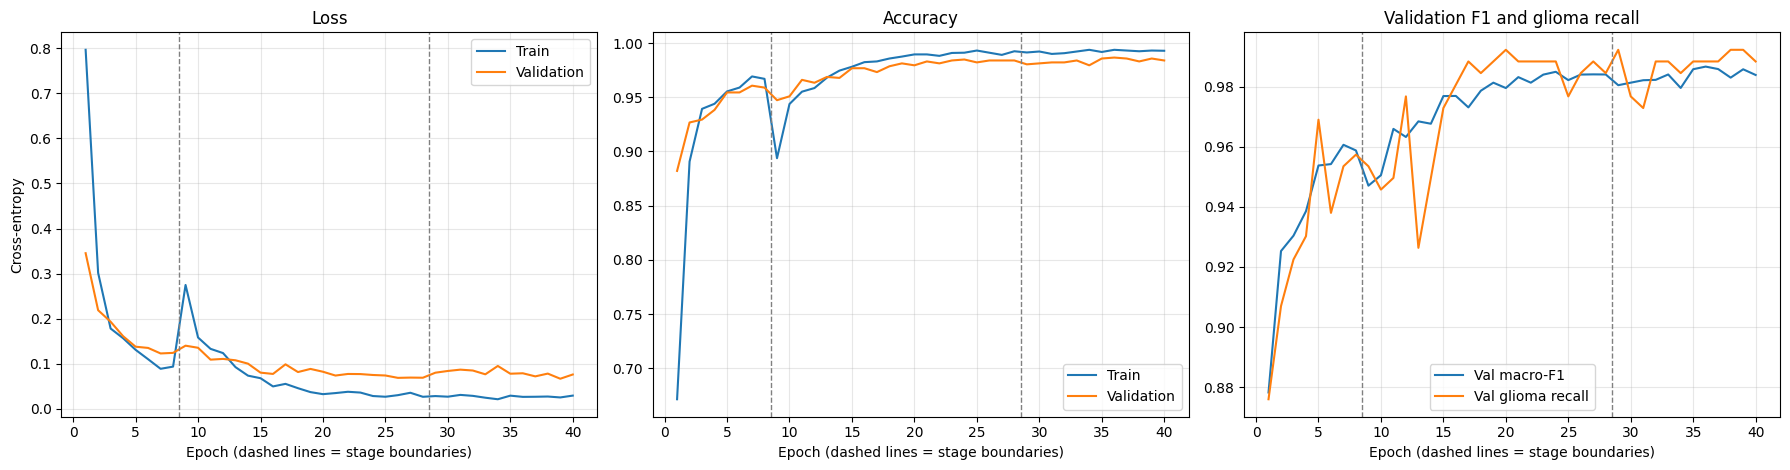

stage                       1       2       3
val_loss          min  0.1227  0.0686  0.0666
                  max  0.3453  0.1400  0.0950
val_acc           min  0.8820  0.9473  0.9794
                  max  0.9607  0.9848  0.9866
val_macro_f1      min  0.8782  0.9470  0.9796
                  max  0.9606  0.9849  0.9867
val_recall_glioma min  0.8760  0.9264  0.9729
                  max  0.9690  0.9922  0.9922
Total training time (min): 79.4


In [66]:
# ===== Cell 6.5: Curves =====
full = pd.concat([HIST[s] for s in sorted(HIST)], ignore_index=True)
full["global_epoch"] = np.arange(1, len(full) + 1)
bounds = full.groupby("stage").size().cumsum().tolist()[:-1]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(full.global_epoch, full.train_loss, label="Train")
axes[0].plot(full.global_epoch, full.val_loss, label="Validation")
axes[0].set_title("Loss"); axes[0].set_ylabel("Cross-entropy")
axes[1].plot(full.global_epoch, full.train_acc, label="Train")
axes[1].plot(full.global_epoch, full.val_acc, label="Validation")
axes[1].set_title("Accuracy")
axes[2].plot(full.global_epoch, full.val_macro_f1, label="Val macro-F1")
axes[2].plot(full.global_epoch, full.val_recall_glioma, label="Val glioma recall")
axes[2].set_title("Validation F1 and glioma recall")
for ax in axes:
    for b in bounds:
        ax.axvline(b + 0.5, ls="--", color="gray", lw=1)
    ax.set_xlabel("Epoch (dashed lines = stage boundaries)")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / "bi_training_curves.png", dpi=150)
plt.show()

full.to_csv(RESULT_DIR / "bi_full_history.csv", index=False)
print(full.groupby("stage")[["val_loss", "val_acc", "val_macro_f1", "val_recall_glioma"]]
      .agg(["min", "max"]).round(4).T.to_string())
print("Total training time (min):", round(sum(i["train_time_s"] for i in INFO.values()) / 60, 1))

In [67]:
# ===== Cell 7.1: Experiment infrastructure =====
import contextlib, gc

SCREEN = dict(s1_epochs=3, s2_epochs=8, patience=4)       # shortened screening protocol

# ---------- MixUp / CutMix (training only), hooked into train_one_epoch via global MIX ----------
MIX = {"mode": None, "prob": 0.5}          # mode: None | "mixup" | "cutmix" | "both"
MIX_ALPHA = {"mixup": 0.2, "cutmix": 1.0}

def _rand_bbox(H, W, lam):
    cut = math.sqrt(1.0 - lam)
    ch, cw = int(H * cut), int(W * cut)
    cy, cx = np.random.randint(H), np.random.randint(W)
    return max(cy - ch // 2, 0), min(cy + ch // 2, H), max(cx - cw // 2, 0), min(cx + cw // 2, W)

def apply_mix(x, y):
    """Returns (x_mixed, y_a, y_b, lam). lam == 1.0 means the batch was not mixed."""
    if MIX["mode"] is None or np.random.rand() > MIX["prob"]:
        return x, y, y, 1.0
    mode = MIX["mode"]
    if mode == "both":
        mode = "mixup" if np.random.rand() < 0.5 else "cutmix"
    a = MIX_ALPHA[mode]
    lam = float(np.random.beta(a, a))
    perm = torch.randperm(x.size(0), device=x.device)
    if mode == "mixup":
        x = lam * x + (1 - lam) * x[perm]
    else:
        y1, y2, x1, x2 = _rand_bbox(x.size(2), x.size(3), lam)
        x[:, :, y1:y2, x1:x2] = x[perm, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (x.size(2) * x.size(3))   # actual kept area
    return x, y, y[perm], lam

def train_one_epoch(model, loader, criterion, optimizer, scaler, scheduler=None,
                    grad_clip=1.0, max_batches=None):
    """Same as Cell 5.3 plus optional MixUp/CutMix. Train accuracy under mixing is approximate."""
    model.train()
    loss_sum = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    for i, (x, y) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        x, ya, yb, lam = apply_mix(x, y)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            logits = model(x)
        logits = logits.float()
        loss = criterion(logits, ya) if lam >= 1.0 else \
               lam * criterion(logits, ya) + (1 - lam) * criterion(logits, yb)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()
        loss_sum += loss.detach() * x.size(0)
        correct += (logits.argmax(1) == (ya if lam >= 0.5 else yb)).sum()
        n += x.size(0)
    avg = (loss_sum / n).item()
    if not math.isfinite(avg):
        raise RuntimeError("Non-finite training loss. Try a lower LR or check inputs.")
    return {"loss": avg, "acc": (correct / n).item()}

# ---------- Temporary config override (dropout, embed_dim) ----------
@contextlib.contextmanager
def cfg_override(**kw):
    old = {k: CFG[k] for k in kw}
    CFG.update(kw)
    try:
        yield
    finally:
        CFG.update(old)

# ---------- Experiment runner with resumable log ----------
EXP_LOG = RESULT_DIR / "experiments.csv"

def _load_log():
    return pd.read_csv(EXP_LOG) if EXP_LOG.exists() else pd.DataFrame()

def run_experiment(name, cfg=None, label_smoothing=0.0, class_weights=None, mix=None,
                   s1_sched="cosine", s2_sched="cosine", warmup=1, force=False):
    log = _load_log()
    if len(log) and name in set(log["name"]) and not force:
        print(f"[skip] '{name}' is already in experiments.csv")
        return
    cfg = cfg or {}
    print(f"\n######## EXPERIMENT '{name}' | cfg={cfg} | LS={label_smoothing} | mix={mix} | "
          f"sched={s1_sched}/{s2_sched} | warmup={warmup} ########")
    t0 = time.time()
    seed_everything(SEED)
    MIX["mode"] = mix
    run = f"exp_{name}"
    infos = {}
    try:
        with cfg_override(**cfg):
            model = build_model("bi", pretrained=True).to(DEVICE)
        _, infos[1] = run_stage(model, run, 1, label_smoothing, class_weights,
                                epochs=SCREEN["s1_epochs"], patience=SCREEN["patience"],
                                scheduler=s1_sched, warmup=warmup)
        _, infos[2] = run_stage(model, run, 2, label_smoothing, class_weights,
                                epochs=SCREEN["s2_epochs"], patience=SCREEN["patience"],
                                scheduler=s2_sched, warmup=warmup)
    finally:
        MIX["mode"] = None            # never leak mixing into later runs

    best_stage = min(infos, key=lambda s: infos[s]["best_value"])
    model.load_state_dict(torch.load(infos[best_stage]["ckpt"], map_location=DEVICE)["state_dict"])
    va = evaluate(model, val_loader)
    row = {"name": name, "cfg": json.dumps(cfg), "label_smoothing": label_smoothing,
           "mix": mix or "none", "sched": f"{s1_sched}/{s2_sched}", "warmup": warmup,
           "params_M": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
           "best_stage": int(best_stage), "val_loss": va["loss"], "val_acc": va["acc"],
           "val_macro_f1": va["macro_f1"], "val_macro_recall": va["macro_recall"],
           "val_recall_glioma": va["recall_glioma"],
           "minutes": round((time.time() - t0) / 60, 1)}
    pd.concat([log, pd.DataFrame([row])], ignore_index=True).to_csv(EXP_LOG, index=False)
    print(f">>> '{name}': val loss {va['loss']:.4f} | acc {va['acc']:.4f} | macro-F1 {va['macro_f1']:.4f} "
          f"| glioma recall {va['recall_glioma']:.3f} | {row['minutes']} min")
    del model
    gc.collect(); torch.cuda.empty_cache()

def show_log():
    log = _load_log()
    if log.empty:
        print("No experiments logged yet."); return log
    cols = ["name", "val_loss", "val_acc", "val_macro_f1", "val_recall_glioma", "best_stage", "params_M", "minutes"]
    print(log[cols].sort_values("val_macro_f1", ascending=False).round(4).to_string(index=False))
    return log

print("Infrastructure ready. Previously logged experiments:",
      list(_load_log()["name"]) if EXP_LOG.exists() else "none")

Infrastructure ready. Previously logged experiments: ['ref', 'ls0.1']


In [68]:
# ===== Cell 7.2: Reference + label smoothing =====
run_experiment("ref")                                  # warm-up + cosine, no smoothing, no mixing
run_experiment("ls0.1", label_smoothing=0.1)

RUN_CLASS_WEIGHTS = False                              # ratio 1.03 -> not justified; optional
if RUN_CLASS_WEIGHTS:
    run_experiment("classw", class_weights=class_weights)
_ = show_log()

[skip] 'ref' is already in experiments.csv
[skip] 'ls0.1' is already in experiments.csv
 name  val_loss  val_acc  val_macro_f1  val_recall_glioma  best_stage  params_M  minutes
ls0.1    0.1359   0.9741        0.9743             0.9729           2     48.97     20.9
  ref    0.0871   0.9696        0.9697             0.9651           2     48.97     20.4


In [69]:
# ===== Cell 7.3: Scheduler / warm-up =====
run_experiment("nowarmup", warmup=0)
run_experiment("plateau", s1_sched="plateau", s2_sched="plateau", warmup=0)
_ = show_log()


######## EXPERIMENT 'nowarmup' | cfg={} | LS=0.0 | mix=None | sched=cosine/cosine | warmup=0 ########

===== EXP_NOWARMUP | Stage 1: heads only (backbones frozen) | up to 3 epochs =====
total 48.97M | trainable 1.28M (of which backbone 0.00M)
  group new_decay    params   1.246M lr 1e-04 wd 1e-04
  group new_nodecay  params   0.031M lr 1e-04 wd 0e+00
Ep 01/3 | train loss 0.4831 acc 0.8188 | val loss 0.2462 acc 0.9017 F1 0.9028 glioma-rec 0.829 | lr 7.52e-05 | 85s *best*
Ep 02/3 | train loss 0.2192 acc 0.9203 | val loss 0.1871 acc 0.9303 F1 0.9287 glioma-rec 0.965 | lr 2.58e-05 | 85s *best*
Ep 03/3 | train loss 0.1667 acc 0.9406 | val loss 0.1672 acc 0.9383 F1 0.9382 glioma-rec 0.922 | lr 1.00e-06 | 85s *best*
Best epoch 3 | val_loss 0.1672 | total 4.3 min

===== EXP_NOWARMUP | Stage 2: partial fine-tuning (top backbone stages) | up to 8 epochs =====
total 48.97M | trainable 35.00M (of which backbone 33.72M)
  group new_decay    params   1.246M lr 5e-05 wd 1e-04
  group new_nodecay  pa

In [1]:
# ===== Cell 7.4: Dropout =====
run_experiment("drop_low",  cfg=dict(attn_drop=0.0, fusion_drop=0.0, head_drop=0.1))
run_experiment("drop_high", cfg=dict(attn_drop=0.2, fusion_drop=0.2, head_drop=0.5))
_ = show_log()

NameError: name 'run_experiment' is not defined

In [ ]:
# ===== Cell 7.5: Embedding dimension =====
run_experiment("dim128", cfg=dict(embed_dim=128))
run_experiment("dim384", cfg=dict(embed_dim=384))
_ = show_log()

In [ ]:
# ===== Cell 7.6: MixUp / CutMix =====
run_experiment("mixup",  mix="mixup")
run_experiment("cutmix", mix="cutmix")
_ = show_log()

In [ ]:
# ===== Cell 7.7: Summary and decision table =====
log = _load_log()
assert "ref" in set(log["name"]), "Run the 'ref' experiment first (Cell 7.2)."
ref = log[log["name"] == "ref"].iloc[0]
NOISE_PP = 0.5

t = log.copy()
t["d_f1_pp"] = (t["val_macro_f1"] - ref["val_macro_f1"]) * 100
t["d_glioma_pp"] = (t["val_recall_glioma"] - ref["val_recall_glioma"]) * 100
t["d_loss"] = t["val_loss"] - ref["val_loss"]
t["verdict"] = np.where(t["name"] == "ref", "reference",
                np.where((t["d_f1_pp"] >= NOISE_PP) & (t["d_glioma_pp"] >= -1.0), "candidate", "no clear gain"))
cols = ["name", "val_macro_f1", "val_acc", "val_recall_glioma", "val_loss",
        "d_f1_pp", "d_glioma_pp", "d_loss", "verdict"]
summary = t[cols].sort_values("val_macro_f1", ascending=False).round(4)
print(summary.to_string(index=False))
summary.to_csv(RESULT_DIR / "experiment_summary.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
order = t.sort_values("val_macro_f1")
ax[0].barh(order["name"], order["val_macro_f1"] * 100)
ax[0].axvline(ref["val_macro_f1"] * 100, color="k", ls="--", lw=1)
ax[0].set_xlabel("Validation macro-F1 (%)")
ax[0].set_xlim(max(0, order["val_macro_f1"].min() * 100 - 2), 100.2)
ax[1].barh(order["name"], order["val_recall_glioma"] * 100)
ax[1].axvline(ref["val_recall_glioma"] * 100, color="k", ls="--", lw=1)
ax[1].set_xlabel("Validation glioma recall (%)")
ax[1].set_xlim(max(0, order["val_recall_glioma"].min() * 100 - 2), 100.2)
plt.tight_layout(); plt.savefig(RESULT_DIR / "experiment_comparison.png", dpi=150); plt.show()
print(f"\nDashed line = reference. Differences below {NOISE_PP} pp are within single-seed noise.")

In [ ]:
# ===== Cell 7.8: Final configuration, full 3-stage run =====
FINAL = dict(cfg={}, label_smoothing=0.0, mix=None, warmup=1)     # <-- EDIT from Cell 7.7 results

seed_everything(SEED)
MIX["mode"] = FINAL["mix"]
try:
    with cfg_override(**FINAL["cfg"]):
        tuned = build_model("bi", pretrained=True).to(DEVICE)
    TUNED_HIST, TUNED_INFO = {}, {}
    for s in (1, 2, 3):
        ov = {"warmup": FINAL["warmup"]} if s < 3 else {}
        TUNED_HIST[s], TUNED_INFO[s] = run_stage(tuned, "bi_tuned", s,
                                                 label_smoothing=FINAL["label_smoothing"], **ov)
finally:
    MIX["mode"] = None

tuned_sel = pick_final(tuned, "bi_tuned", TUNED_INFO)
with open(CKPT_DIR / "bi_tuned_config.json", "w") as f:
    json.dump({"final": FINAL, "selected_stage": tuned_sel["selected_stage"]}, f, indent=2)

# Compare with the Step 6 reference model on VALIDATION data
if "bi_model" in globals() and "selection" in globals():
    print("\nStep 6 default model | val metrics:",
          {k: round(v, 4) for k, v in selection["val_metrics"].items() if k in ("loss", "acc", "macro_f1", "recall_glioma")})
print("Tuned model          | val metrics:",
      {k: round(v, 4) for k, v in tuned_sel["val_metrics"].items() if k in ("loss", "acc", "macro_f1", "recall_glioma")})